In [1]:
import pandas as pd
from pathlib import Path

In [2]:
# data path
DATA_PATH = Path(
    r"C:\Users\jchmo\Downloads\dataset_football_matches\big5"
)

In [3]:
# dictionary of the league names
league_names = {
    "E0": "Premier League",
    "D1": "Bundesliga",
    "I1": "Serie A",
    "SP1": "La Liga",
    "F1": "Ligue 1"
}

In [4]:
# load all the data
dataframes = []

for file in sorted(DATA_PATH.glob("*.csv")):

    # eg. E0_2122
    file_name = file.stem

    # split the name to season and league
    league_code, season_code = file_name.split("_")

    # league name
    league = league_names[league_code]

    # 2122 -> 2021/22
    start_year = 2000 + int(season_code[:2])
    end_year = 2000 + int(season_code[2:])

    season = f"{start_year}/{str(end_year)[-2:]}"

    # load CSV
    try:
        df_temp = pd.read_csv(file, encoding="utf-8-sig")
    except UnicodeDecodeError:
        df_temp = pd.read_csv(file, encoding="cp1252")

    # delete empty columns
    df_temp.columns = df_temp.columns.str.strip()

    # add info about league and season
    df_temp["Season"] = season
    df_temp["League"] = league
    df_temp["LeagueCode"] = league_code

    # save the data to dataframe
    dataframes.append(df_temp)

# concatenate all dataframes
df = pd.concat(
    dataframes,
    ignore_index=True,
    sort=False
)

In [5]:
print("\nSum of matches from season and league:")
print(df.groupby(["Season", "League"])
      .size()
      .unstack(fill_value=0)    
)


Sum of matches from season and league:
League   Bundesliga  La Liga  Ligue 1  Premier League  Serie A
Season                                                        
2021/22         306      380      380             380      380
2022/23         306      380      380             380      380
2023/24         306      380      306             380      380
2024/25         306      380      306             380      380
2025/26         306      380      306             380      380


In [7]:
print(df.columns.to_list())

['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'IWH', 'IWD', 'IWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'VCH', 'VCD', 'VCA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'B365CH', 'B365CD', 'B365CA', 'BWCH', 'BWCD', 'BWCA', 'IWCH', 'IWCD', 'IWCA', 'PSCH', 'PSCD', 'PSCA', 'WHCH', 'WHCD', 'WHCA', 'VCCH', 'VCCD', 'VCCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'B365C>2.5', 'B365C<2.5', 'PC>2.5', 'PC<2.5', 'MaxC>2.5', 'MaxC<2.5', 'AvgC>2.5', 'AvgC<2.5', 'AHCh', 'B365CAHH', 'B365CAHA', 'PCAHH', 'PCAHA', 'MaxCAHH', 'MaxCAHA', 'AvgCAHH', 'AvgCAHA', 'Season', 'League', 'LeagueCode', 'BFH', 'BFD', 'BFA', '1XBH', '1XBD', '1XBA', 'BFEH', 'B

FTR                     H          D          A
League                                         
Bundesliga      44.052288  24.901961  31.045752
La Liga         45.736842  26.157895  28.105263
Ligue 1         43.444577  24.553039  32.002384
Premier League  44.157895  23.894737  31.947368
Serie A         40.368421  27.210526  32.421053


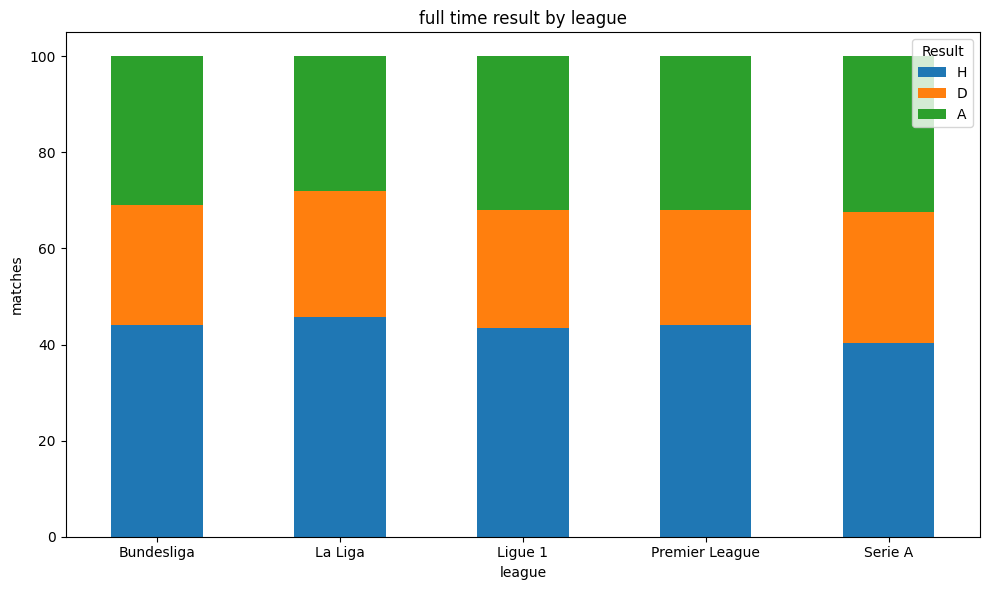

In [12]:
results_by_league = pd.crosstab(
    df["League"],
    df["FTR"],
    normalize="index",
) * 100
results_by_league = results_by_league[["H", "D", "A"]]
print(results_by_league)

import matplotlib.pyplot as plt
results_by_league.plot(kind="bar", stacked = True, figsize=(10,6))
plt.title("full time result by league")
plt.xlabel("league")
plt.ylabel("matches")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.tight_layout()
plt.show()

In [21]:
# hypothesis test - does home advantage matter?
from scipy.stats import chisquare
# choose matches without a draw
decisive_matches = df[df["FTR"].isin(["H", "A"])]

home_wins = (decisive_matches["FTR"] == "H").sum()
away_wins = (decisive_matches["FTR"] == "A").sum()

observed = [home_wins, away_wins]

expected = [sum(observed) / 2, sum(observed) / 2]

chi2, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print("home wins: ", home_wins, "away wins: ", away_wins)
print("chi-square: ", chi2)
print("p-value: ", p_value)

home wins:  3878 away wins:  2769
chi-square:  185.02798254851814
p-value:  3.869805720090763e-42
